# Analyse du dataset

## 1. 

## 1. Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuration esthétique globale
sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# Chargement des données
df = pd.read_csv("results_pipeline.csv")

# Variables utilisées
df["target_coverage"] = 1.0 - df["alpha"] #couverture
df["coverage_gap"] = df["coverage"] - df["target_coverage"]  # > 0 : sur-couverture, < 0 : sous-couverture
df["norm_set_size"] = df["avg_set_size"] / df["n_classes"]   # Taille relative au nombre de classes

print(f"Dimensions du dataset : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print(f"Datasets uniques ({df['dataset'].nunique()}) | Modèles : {df['modele'].unique().tolist()}")
print(f"Méthodes : {df['methode'].unique().tolist()} | Scores : {df['score'].unique().tolist()} | Alphas : {df['alpha'].unique().tolist()}")
display(df.head())

Dimensions du dataset : 1377 lignes × 25 colonnes
Datasets uniques (34) | Modèles : ['XGBClassifier', 'TabICLClassifier']
Méthodes : ['split', 'cv+', 'jackknife+'] | Scores : ['lac', 'aps', 'raps'] | Alphas : [0.05, 0.1, 0.2]


,dataset,modele,methode,score,alpha,graine,lam,k_reg,coverage,avg_set_size,...,recall_macro,f1_macro,n_samples,n_doublons,n_features,n_classes,temps_s,target_coverage,coverage_gap,norm_set_size
0,blood-transfusion-service-center,XGBClassifier,split,lac,0.05,90,NaN,NaN,0.947761,1.656716,...,0.581638,0.586125,533,215,4,2,0.277858,0.95,-0.002239,0.828358
1,blood-transfusion-service-center,XGBClassifier,split,lac,0.10,90,NaN,NaN,0.940299,1.544776,...,0.581638,0.586125,533,215,4,2,0.277858,0.90,0.040299,0.772388
2,blood-transfusion-service-center,XGBClassifier,split,lac,0.20,90,NaN,NaN,0.858209,1.335821,...,0.581638,0.586125,533,215,4,2,0.277858,0.80,0.058209,0.667910
3,blood-transfusion-service-center,XGBClassifier,split,aps,0.05,90,NaN,NaN,0.910448,1.611940,...,0.581638,0.586125,533,215,4,2,0.277858,0.95,-0.039552,0.805970
4,blood-transfusion-service-center,XGBClassifier,split,aps,0.10,90,NaN,NaN,0.910448,1.604478,...,0.581638,0.586125,533,215,4,2,0.277858,0.90,0.010448,0.802239


# 2. Tableau récapitulatif

In [2]:
# Tableau récapitulatif pour alpha = 0.10 (cible de couverture = 90%)
sub_10 = df[df["alpha"] == 0.10]

summary = (
    sub_10.groupby(["modele", "methode", "score"])
    .agg(
        n_datasets=("dataset", "nunique"),
        coverage_mean=("coverage", "mean"),
        coverage_std=("coverage", "std"),
        avg_set_size=("avg_set_size", "mean"),
        norm_set_size=("norm_set_size", "mean"),
        singleton_rate=("singleton_rate", "mean"),
        multi_rate=("multi_rate", "mean"),
        empty_rate=("empty_rate", "mean"),
        accuracy=("accuracy", "mean"),
        f1_macro=("f1_macro", "mean"),
        temps_median_s=("temps_s", "median"),
    )
    .round(4)
)

display(summary)

n_datasets  coverage_mean  coverage_std  \
modele           methode    score                                            
TabICLClassifier cv+        aps            29         0.9363        0.0352   
                            lac            29         0.9038        0.0146   
                            raps           29         0.9385        0.0353   
                 jackknife+ aps            12         0.9347        0.0497   
                            lac            12         0.9078        0.0221   
                            raps           12         0.9415        0.0465   
                 split      aps            30         0.9151        0.0285   
                            lac            30         0.8984        0.0166   
                            raps           30         0.9160        0.0290   
XGBClassifier    cv+        aps            34         0.9479        0.0349   
                            lac            34         0.9072        0.0110   
                            raps           34         0.9490        0.0349   
                 jackknife+ aps            14         0.9381        0.0432   
                            lac            14         0.8974        0.0135   
                            raps           14         0.9385        0.0455   
                 split      aps            34         0.9245        0.0292   
                            lac            34         0.9000        0.0132   
                            raps           34         0.9231        0.0297   

                                   avg_set_size  norm_set_size  \
modele           methode    score                                
TabICLClassifier cv+        aps          1.5657         0.6569   
                            lac          1.1445         0.5198   
                            raps         1.4196         0.6307   
                 jackknife+ aps          1.8704         0.6794   
                            lac          1.1791         0.4944   
                            raps         1.5224         0.6229   
                 split      aps          1.5134         0.6356   
                            lac          1.1404         0.5209   
                            raps         1.3595         0.6089   
XGBClassifier    cv+        aps          1.5722         0.6768   
                            lac          1.1554         0.5268   
                            raps         1.4235         0.6461   
                 jackknife+ aps          1.7639         0.6741   
                            lac          1.1802         0.4950   
                            raps         1.4590         0.6167   
                 split      aps          1.5287         0.6604   
                            lac          1.1479         0.5237   
                            raps         1.3756         0.6293   

                                   singleton_rate  multi_rate  empty_rate  \
modele           methode    score                                           
TabICLClassifier cv+        aps            0.5299      0.4483      0.0219   
                            lac            0.8094      0.1654      0.0252   
                            raps           0.5909      0.3920      0.0170   
                 jackknife+ aps            0.3857      0.5859      0.0284   
                            lac            0.7970      0.1863      0.0168   
                            raps           0.5116      0.4724      0.0160   
                 split      aps            0.5698      0.4067      0.0235   
                            lac            0.8112      0.1629      0.0259   
                            raps           0.6281      0.3521      0.0198   
XGBClassifier    cv+        aps            0.4998      0.4826      0.0176   
                            lac            0.8071      0.1709      0.0219   
                            raps           0.5752      0.4106      0.0142   
                 jackknife+ aps            0.3883      0.5887      0.0230  

# 3. Etude du coverage

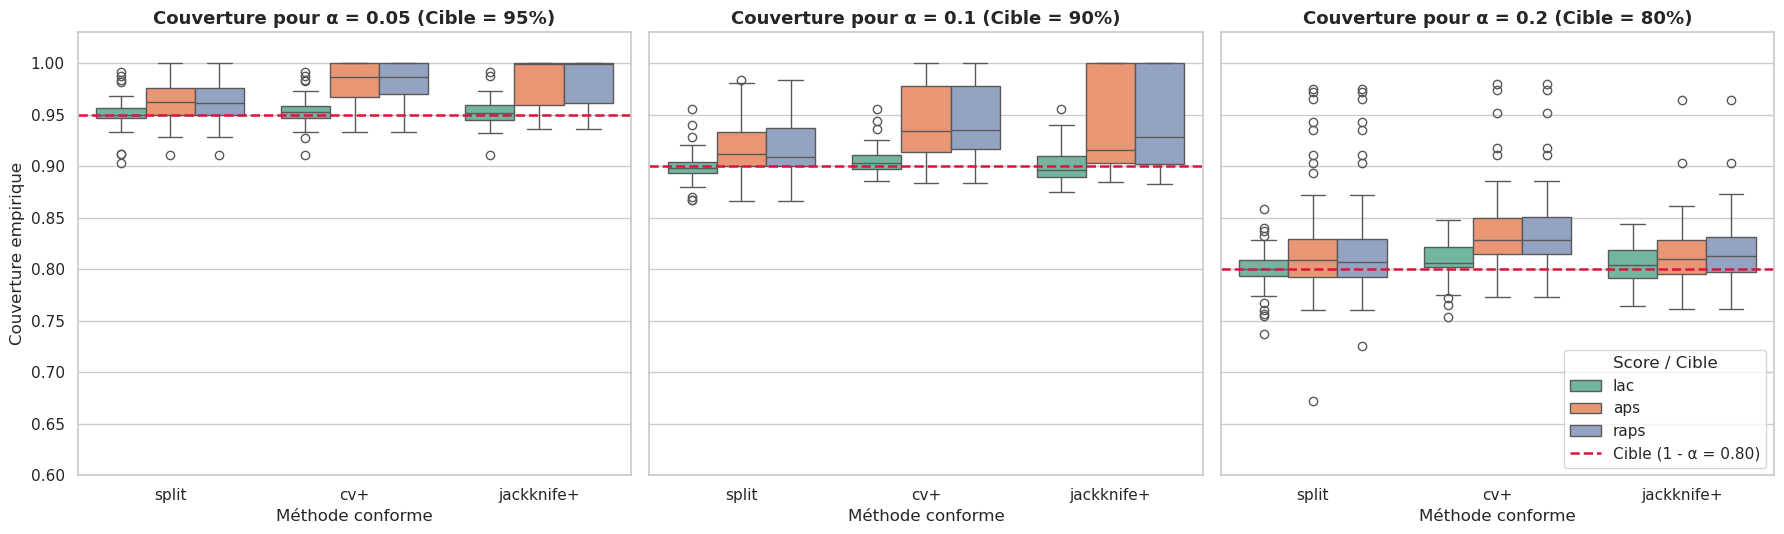

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
alphas = sorted(df["alpha"].unique())

for ax, a in zip(axes, alphas):
    sub = df[df["alpha"] == a]
    sns.boxplot(
        data=sub, x="methode", y="coverage", hue="score",
        order=["split", "cv+", "jackknife+"], hue_order=["lac", "aps", "raps"],
        ax=ax, palette="Set2"
    )
    ax.axhline(1 - a, color="crimson", linestyle="--", linewidth=1.8, label=f"Cible (1 - α = {1-a:.2f})")
    ax.set_title(f"Couverture pour α = {a} (Cible = {1-a:.0%})")
    ax.set_xlabel("Méthode conforme")
    ax.set_ylabel("Couverture empirique" if a == alphas[0] else "")
    ax.set_ylim(0.60, 1.03)
    if a != alphas[-1]:
        ax.get_legend().remove()
    else:
        ax.legend(title="Score / Cible", loc="lower right")

plt.tight_layout()
plt.show()


lac: least ambigous set classifier: 1-p(y) avec p(y) la proba de la vraie classe: plus c'est proche de 0 plus le modele est conforme : efficace sur peu de classes

aps: efficace avec bcp de classe, on somme les probas des classes pour avoir le minimum du seuil étudié

raps: aps régularisé, pénalité de regularisation (kreg et lambda) : l'ensemble de prediction peut devenir inutilement grand si il y a beaucoup de classe a faible proba


la couverture est une variable aléatoire qui fluctue naturellement autour de 1-alpha, garantie moyenne sur le hasard du découpage :
théorie de cv+ et jackknife+: 1-2alpha

analyse boxplot: chaque point est un datatset (c'est le score empirique moyen des elements du test de ce dataset)

les scores orange et bleus sont valides (au dessus du seuil) mais plus large.

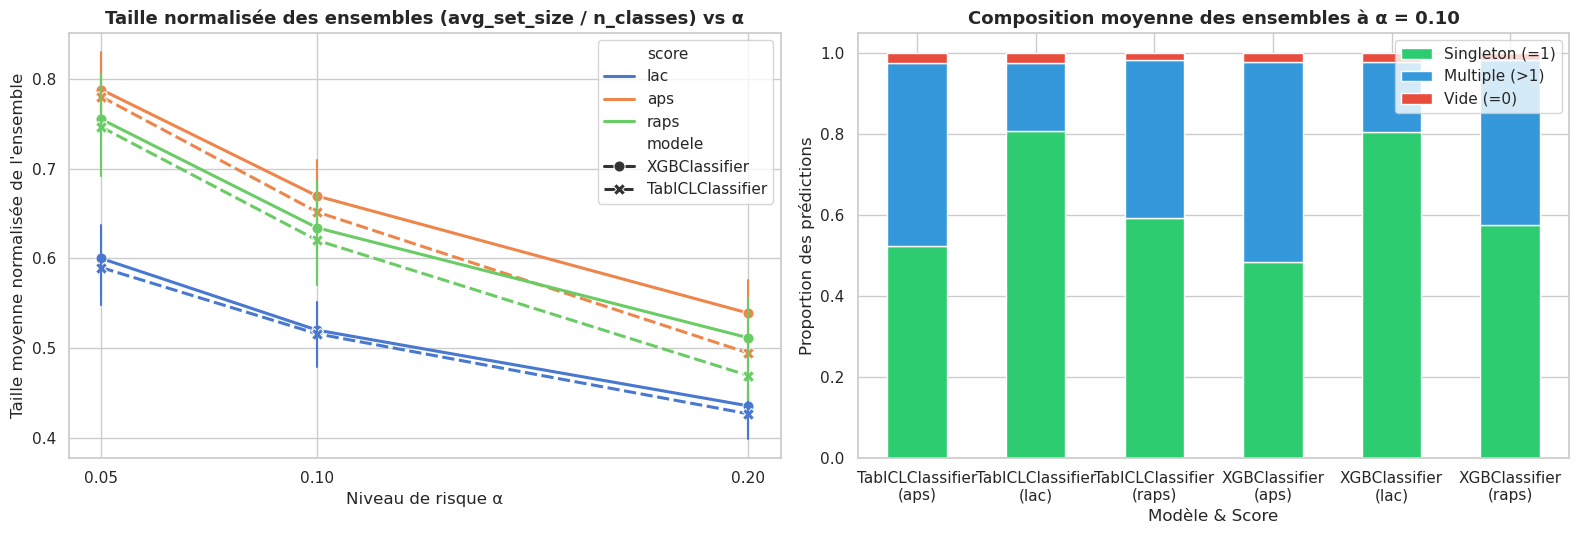

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# 1. Taille normalisée des ensembles selon alpha et score
sns.lineplot(
    data=df, x="alpha", y="norm_set_size", hue="score", style="modele",
    markers=True, dashes=True, err_style="bars", linewidth=2.2, markersize=8, ax=axes[0]
)
axes[0].set_title("Taille normalisée des ensembles (avg_set_size / n_classes) vs α")
axes[0].set_xlabel("Niveau de risque α")
axes[0].set_ylabel("Taille moyenne normalisée de l'ensemble")
axes[0].set_xticks(alphas)

# 2. Composition empilée des prédictions (Singleton / Multi / Empty) pour alpha = 0.10
comp = (
    df[df["alpha"] == 0.10]
    .groupby(["modele", "score"])[["singleton_rate", "multi_rate", "empty_rate"]]
    .mean()
)
comp.plot(
    kind="bar", stacked=True, ax=axes[1],
    color=["#2ecc71", "#3498db", "#e74c3c"], edgecolor="white"
)
axes[1].set_title("Composition moyenne des ensembles à α = 0.10")
axes[1].set_xlabel("Modèle & Score")
axes[1].set_ylabel("Proportion des prédictions")
axes[1].set_xticklabels([f"{m}\n({s})" for m, s in comp.index], rotation=0)
axes[1].legend(["Singleton (=1)", "Multiple (>1)", "Vide (=0)"], loc="upper right")

plt.tight_layout()
plt.show()

cohérent, plus on est précis plus on est large (tendance plus exponentielle que linéaire ?)
tabicl est systematiquement plus petit que xgb

le score lac semble etre plus pertinent pour alpha =0.1

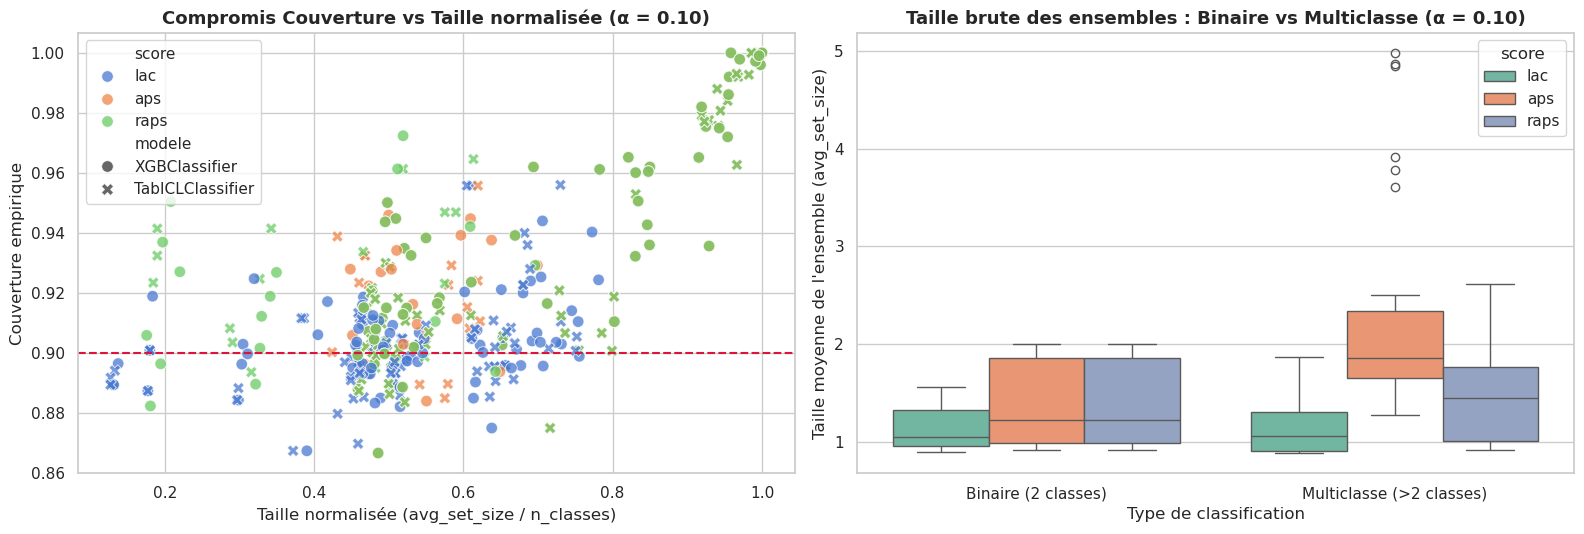

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Scatter Couverture vs Taille normalisée (alpha = 0.10)
df["type_probleme"] = np.where(df["n_classes"] == 2, "Binaire (2 classes)", "Multiclasse (>2 classes)")
sub_10 = df[df["alpha"] == 0.10]

sns.scatterplot(
    data=sub_10, x="norm_set_size", y="coverage",
    hue="score", style="modele", alpha=0.75, s=70, ax=axes[0]
)
axes[0].axhline(0.90, color="crimson", linestyle="--", label="Cible 90%")
axes[0].set_title("Compromis Couverture vs Taille normalisée (α = 0.10)")
axes[0].set_xlabel("Taille normalisée (avg_set_size / n_classes)")
axes[0].set_ylabel("Couverture empirique")

# Taille moyenne en fonction du nombre de classes (binaire vs multiclasse)
sns.boxplot(
    data=sub_10, x="type_probleme", y="avg_set_size", hue="score",
    palette="Set2", ax=axes[1]
)
axes[1].set_title("Taille brute des ensembles : Binaire vs Multiclasse (α = 0.10)")
axes[1].set_xlabel("Type de classification")
axes[1].set_ylabel("Taille moyenne de l'ensemble (avg_set_size)")

plt.tight_layout()
plt.show()

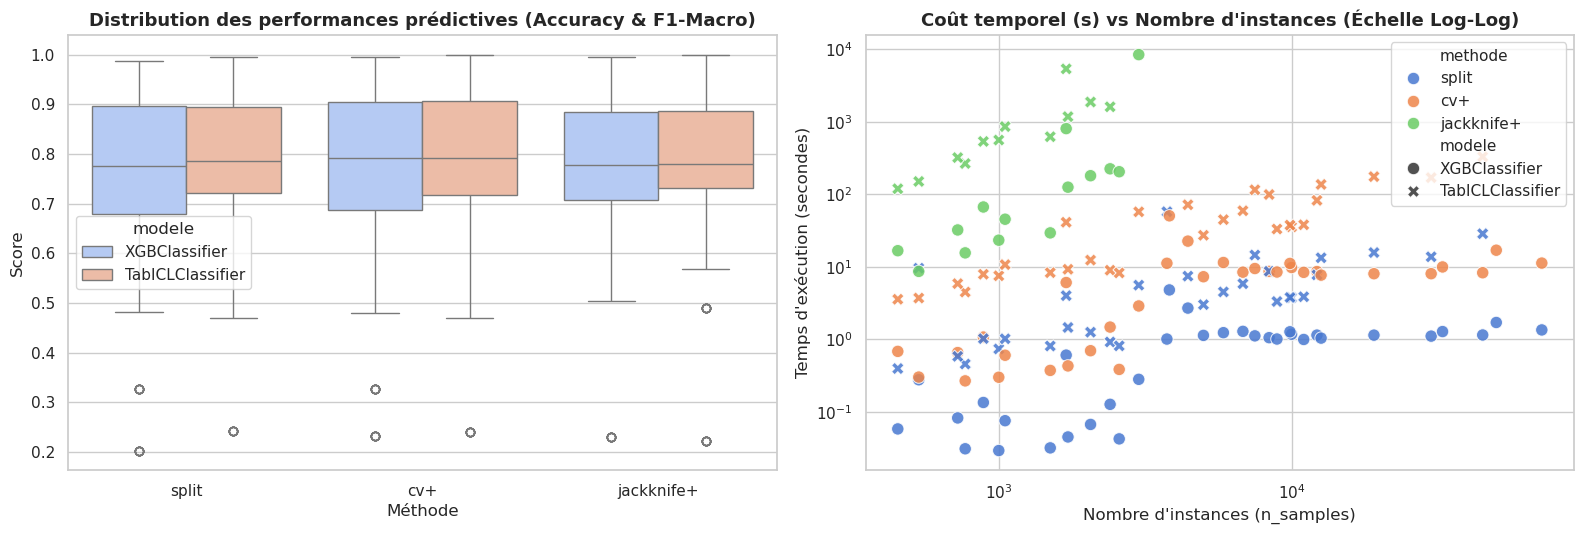

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Comparaison Accuracy & F1 entre modèles et méthodes
perf_melt = df.melt(
    id_vars=["dataset", "modele", "methode"],
    value_vars=["accuracy", "f1_macro"],
    var_name="Metrique", value_name="Valeur"
)
sns.boxplot(
    data=perf_melt, x="methode", y="Valeur", hue="modele",
    order=["split", "cv+", "jackknife+"], palette="coolwarm", ax=axes[0]
)
axes[0].set_title("Distribution des performances prédictives (Accuracy & F1-Macro)")
axes[0].set_xlabel("Méthode")
axes[0].set_ylabel("Score")

# Temps d'exécution en fonction de la taille du dataset (échelle log-log)
sns.scatterplot(
    data=df.drop_duplicates(subset=["dataset", "modele", "methode"]),
    x="n_samples", y="temps_s", hue="methode", style="modele",
    s=80, alpha=0.85, ax=axes[1]
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Coût temporel (s) vs Nombre d'instances (Échelle Log-Log)")
axes[1].set_xlabel("Nombre d'instances (n_samples)")
axes[1].set_ylabel("Temps d'exécution (secondes)")

plt.tight_layout()
plt.show()

# clustering

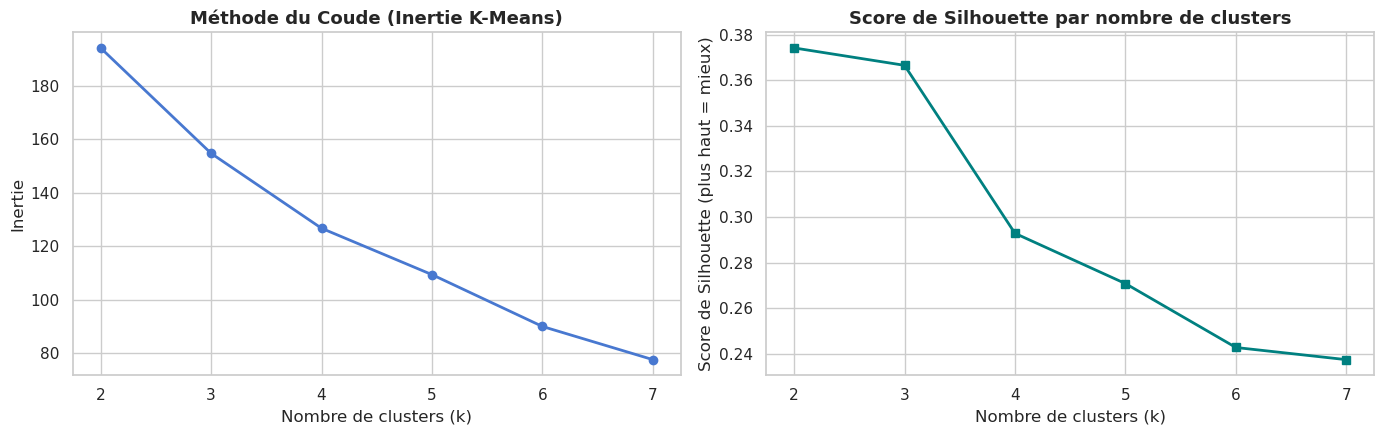

In [9]:
# 1. Construction de la table agrégée par dataset (sur alpha = 0.10)
features_cluster = [
    "n_samples", "n_features", "n_classes",
    "accuracy", "f1_macro",
    "coverage", "norm_set_size", "singleton_rate", "multi_rate", "empty_rate"
]

df_ds = (
    df[df["alpha"] == 0.10]
    .groupby("dataset")[features_cluster]
    .mean()
    .dropna()
)

# Transformation log1p sur n_samples et n_features pour éviter qu'ils dominent la variance
X_clust = df_ds.copy()
X_clust["n_samples"] = np.log1p(X_clust["n_samples"])
X_clust["n_features"] = np.log1p(X_clust["n_features"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clust)

# 2. Recherche du nombre optimal de clusters (Inertie + Score de Silhouette)
inertias, silhouettes = [], []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(K_range, inertias, marker="o", linewidth=2)
axes[0].set_title("Méthode du Coude (Inertie K-Means)")
axes[0].set_xlabel("Nombre de clusters (k)")
axes[0].set_ylabel("Inertie")

axes[1].plot(K_range, silhouettes, marker="s", color="teal", linewidth=2)
axes[1].set_title("Score de Silhouette par nombre de clusters")
axes[1].set_xlabel("Nombre de clusters (k)")
axes[1].set_ylabel("Score de Silhouette (plus haut = mieux)")
plt.tight_layout()
plt.show()

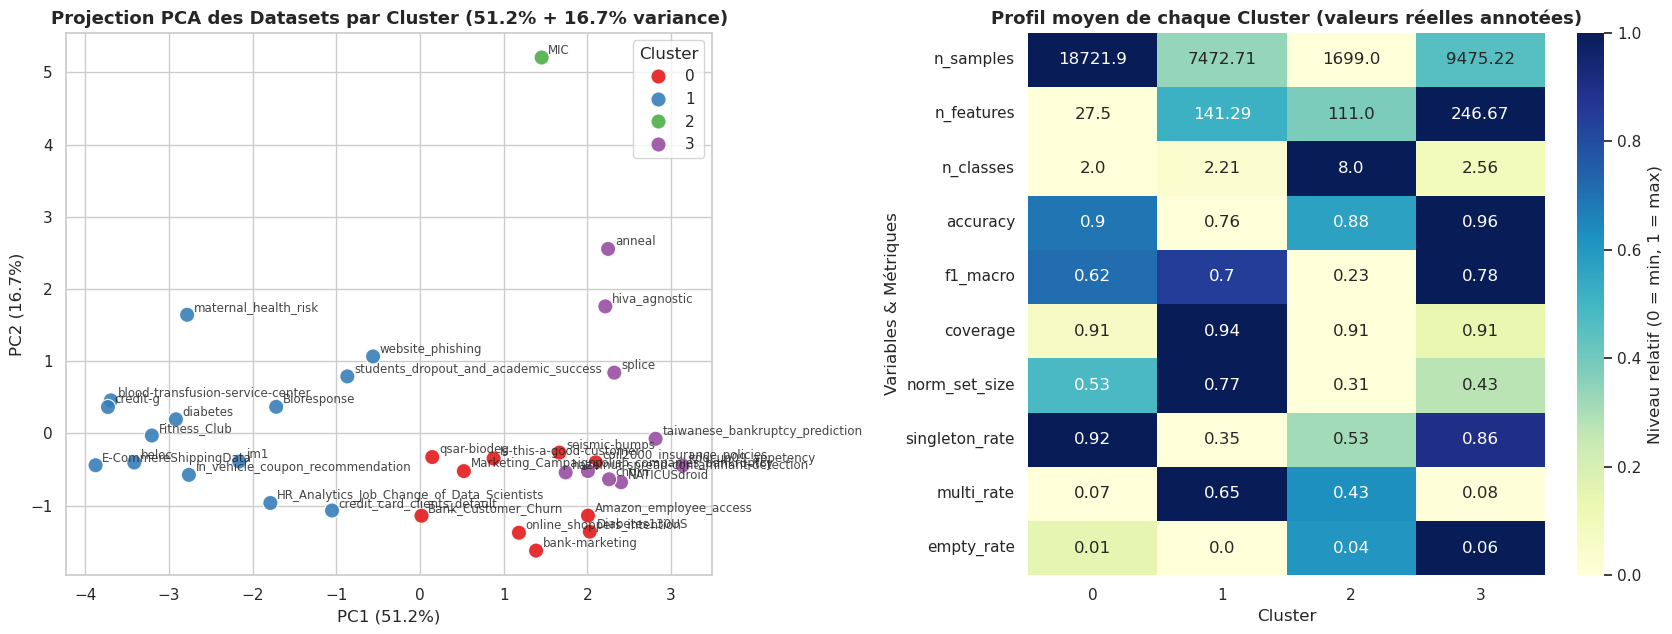


🔹 Cluster 0 (10 datasets) : Amazon_employee_access, Bank_Customer_Churn, Diabetes130US, Is-this-a-good-customer, Marketing_Campaign, bank-marketing, coil2000_insurance_policies, online_shoppers_intention, qsar-biodeg, seismic-bumps

🔹 Cluster 1 (14 datasets) : Bioresponse, E-CommereShippingData, Fitness_Club, HR_Analytics_Job_Change_of_Data_Scientists, blood-transfusion-service-center, credit-g, credit_card_clients_default, diabetes, heloc, in_vehicle_coupon_recommendation, jm1, maternal_health_risk, students_dropout_and_academic_success, website_phishing

🔹 Cluster 2 (1 datasets) : MIC

🔹 Cluster 3 (9 datasets) : NATICUSdroid, anneal, churn, hazelnut-spread-contaminant-detection, hiva_agnostic, kddcup09_appetency, polish_companies_bankruptcy, splice, taiwanese_bankruptcy_prediction


In [10]:
# 3. Application du clustering final (k = 4 clusters) et projection PCA 2D
K_OPT = 4
kmeans = KMeans(n_clusters=K_OPT, random_state=42, n_init=20)
df_ds["cluster"] = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
df_ds["PC1"] = coords[:, 0]
df_ds["PC2"] = coords[:, 1]

var_exp = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

# Projection PCA avec noms des datasets
palette_clust = sns.color_palette("Set1", K_OPT)
sns.scatterplot(
    data=df_ds, x="PC1", y="PC2", hue="cluster",
    palette=palette_clust, s=120, alpha=0.9, ax=axes[0]
)
for ds_name, row in df_ds.iterrows():
    axes[0].text(row["PC1"] + 0.08, row["PC2"] + 0.05, ds_name, fontsize=8.5, alpha=0.85)

axes[0].set_title(f"Projection PCA des Datasets par Cluster ({var_exp[0]:.1f}% + {var_exp[1]:.1f}% variance)")
axes[0].set_xlabel(f"PC1 ({var_exp[0]:.1f}%)")
axes[0].set_ylabel(f"PC2 ({var_exp[1]:.1f}%)")
axes[0].legend(title="Cluster")

# Heatmap des profils moyens normalisés par cluster
cluster_means = df_ds.groupby("cluster")[features_cluster].mean()
cluster_means_norm = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min() + 1e-9)

sns.heatmap(
    cluster_means_norm.T, annot=cluster_means.T.round(2), fmt="",
    cmap="YlGnBu", cbar_kws={"label": "Niveau relatif (0 = min, 1 = max)"}, ax=axes[1]
)
axes[1].set_title("Profil moyen de chaque Cluster (valeurs réelles annotées)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Variables & Métriques")

plt.tight_layout()
plt.show()

# Liste détaillée des datasets par cluster
for c in range(K_OPT):
    noms = df_ds[df_ds["cluster"] == c].index.tolist()
    print(f"\n🔹 Cluster {c} ({len(noms)} datasets) : {', '.join(noms)}")

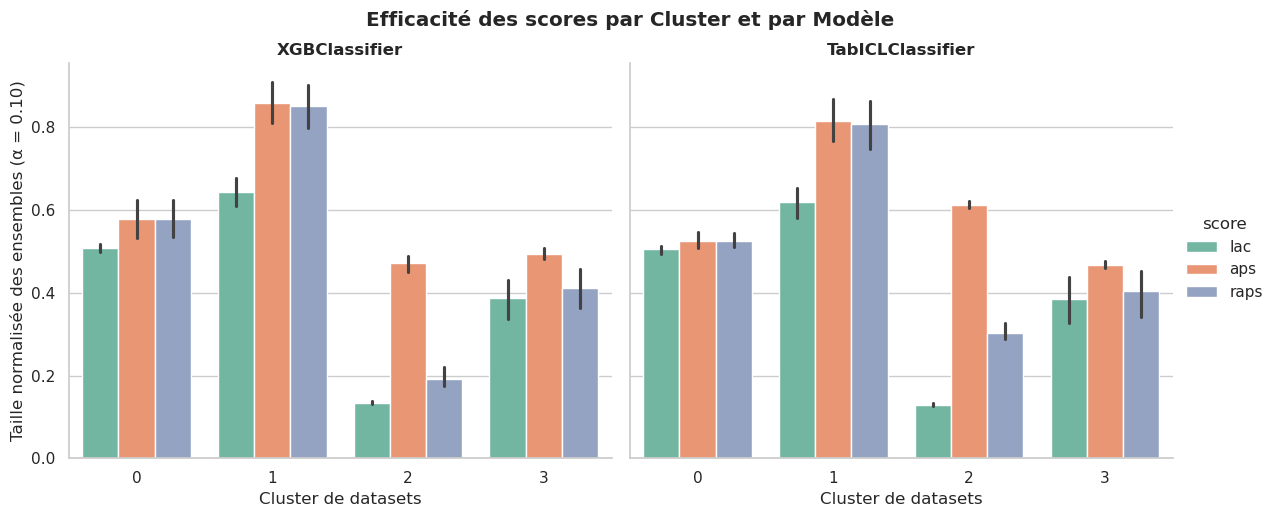

In [11]:
df_merged = df[df["alpha"] == 0.10].merge(df_ds[["cluster"]], on="dataset")

g = sns.catplot(
    data=df_merged, x="cluster", y="norm_set_size",
    hue="score", col="modele", kind="bar",
    palette="Set2", height=5, aspect=1.2
)
g.set_titles("{col_name}")
g.set_axis_labels("Cluster de datasets", "Taille normalisée des ensembles (α = 0.10)")
g.fig.suptitle("Efficacité des scores par Cluster et par Modèle", y=1.03, fontweight="bold")
plt.show()